# Scan strategies: the opening scan over the answers

When the answer screen appears, in what order do people first look over the four answers, and does each person have a habit? For each trial, the fixations are merged into visits (several fixations in a row on one area count as one visit), visits to the question are removed, and the first four answer visits, named by their place on the screen and repeats included, form the trial's **opening scan**: a window long enough for a full circuit of the four answers, if the person makes one. A participant **has a dominant strategy** if their most common opening scan covers at least half of their trials.

The data are Study 1 (360 participants, 19,436 trials), read from the word-level table and reduced to one row per trial. Scans that stopped before four visits can be **completed** the way the same start is most often completed in the dataset, and the numbers are shown before and after this repair. "Dominant" means most common, not the only one: people with a dominant scan still use many others. The same sequences also give heatmaps of the first and last visits, and a count of dominant scans by the eye the tracker recorded, which is descriptive only.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import pandas as pd
pd.set_option("display.max_colwidth", None)   # show whole scans, not truncated ones
from src.config import columns as C
from src.config.datasets import dataset
from src.features.build import load_model_input
from src.features.scope import split_participant_groups
from src.features.strategies import (
    add_completed_strategy_column,
    build_prefix_completion_map,
    build_starting_strategies,
)
from src.analyses.scan_strategies.plots import (
    matrix_plot_simplified_visits,
    plot_dominance_gap,
    plot_dominant_strategy_counts_above_threshold,
    plot_dominant_strategy_hist,
    plot_strategy_count_distribution,
    proportion_with_dominant_strategy,
    summarize_before_after,
)
from src.analyses.scan_strategies.dominant_eye import (
    build_dominant_strategy_by_eye,
    plot_dominant_strategies_by_eye_sorted,
)

# One row per word; each trial's values, including its fixation sequences, repeat on every word.
all_participants = load_model_input(dataset("l1"))

  grains: interest_areas (760628, 23), areas_answers (97180, 19), trials (19436, 89)


## 1. The opening scan of each trial

`build_starting_strategies` keeps one row per trial and takes the first four entries of the merged sequence by screen position (`simpl_fix_by_loc`), after removing the question. The four positions are `answer_0(top)`, `answer_1(left)`, `answer_2(right)` and `answer_3(bottom)`. A position can appear twice, e.g. top, right, bottom, right, when someone goes back to an answer before reaching the fourth.

Scans shorter than four are then completed with a map learned once from all the full-length scans in the dataset: `strategy_completed` holds the result and `strategy_was_completed` marks the trials it changed. `question_preview` is carried along so the table can be split into hunters (`True`: saw the question before the text) and gatherers (`False`).

In [2]:
per_trial = build_starting_strategies(
    all_participants,
    kind="location",
    window_len=4,
    drop_question=True,
    out_col=C.STRATEGY_COL,
    keep_cols=[C.QUESTION_PREVIEW_COLUMN],
)
completion_map = build_prefix_completion_map(per_trial[C.STRATEGY_COL], full_len=4)
per_trial, _ = add_completed_strategy_column(
    per_trial, strat_col=C.STRATEGY_COL, full_len=4, prefix2full=completion_map
)
print(f"{len(per_trial):,} trials; {per_trial['strategy_was_completed'].mean():.1%} had fewer than four answer visits")
per_trial.head()

19,436 trials; 3.5% had fewer than four answer visits


,participant_id,TRIAL_INDEX,question_preview,strategy,strategy_was_completed,strategy_completed
0,l42_2070,4,True,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",False,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))"
1,l42_2070,5,True,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",False,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))"
2,l42_2070,6,True,"(answer_0(top), answer_2(right), answer_3(bottom), answer_2(right))",False,"(answer_0(top), answer_2(right), answer_3(bottom), answer_2(right))"
3,l42_2070,7,True,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",False,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))"
4,l42_2070,8,True,"(answer_0(top), answer_2(right), answer_3(bottom), answer_2(right))",False,"(answer_0(top), answer_2(right), answer_3(bottom), answer_2(right))"


The most common opening scans over all trials. The first is the clockwise circuit (top, right, bottom, left); the second is the counter-clockwise one (top, left, bottom, right).

In [3]:
counts = per_trial[C.STRATEGY_COL].value_counts()
top = counts.head(6).rename("trials").to_frame()
top["% of trials"] = (100 * top["trials"] / counts.sum()).round(1)
top

,trials,% of trials
strategy,,
"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",8075,41.5
"(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))",3774,19.4
"(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))",1209,6.2
"(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))",1026,5.3
"(answer_0(top), answer_2(right), answer_3(bottom), answer_2(right))",485,2.5
"(answer_0(top), answer_2(right), answer_1(left), answer_3(bottom))",481,2.5


The same question per participant: each person's own most common opening scan (raw scans), and the share of all 360 participants for whom it is the clockwise or the counter-clockwise circuit.

In [4]:
from src.features.strategies import dominant_strategy_by_participant

CLOCKWISE = ("answer_0(top)", "answer_2(right)", "answer_3(bottom)", "answer_1(left)")
COUNTER_CLOCKWISE = ("answer_0(top)", "answer_1(left)", "answer_3(bottom)", "answer_2(right)")

modal = dominant_strategy_by_participant(per_trial, strat_col=C.STRATEGY_COL)
modal_scan = modal[C.DOMINANT_STARTING_STRATEGY]
pd.Series({
    "participants": len(modal),
    "% whose most common scan is clockwise": round(100 * (modal_scan == CLOCKWISE).mean(), 1),
    "% whose most common scan is counter-clockwise": round(100 * (modal_scan == COUNTER_CLOCKWISE).mean(), 1),
})

participants                                     360.0
% whose most common scan is clockwise             63.1
% whose most common scan is counter-clockwise     26.4
dtype: float64

The same, only for the participants who have a dominant strategy: their most common scan covers at least half of their trials (raw scans).

In [5]:
from src.features.strategies import has_dominant_strategy

dominant_only = modal[has_dominant_strategy(modal[C.DOMINANCE_SCORE], threshold=0.5)]
dominant_scan = dominant_only[C.DOMINANT_STARTING_STRATEGY]
pd.Series({
    "participants with a dominant strategy": len(dominant_only),
    "% whose dominant scan is clockwise": round(100 * (dominant_scan == CLOCKWISE).mean(), 1),
    "% whose dominant scan is counter-clockwise": round(100 * (dominant_scan == COUNTER_CLOCKWISE).mean(), 1),
})

participants with a dominant strategy         217.0
% whose dominant scan is clockwise             74.7
% whose dominant scan is counter-clockwise     19.4
dtype: float64

## 2. Who has a dominant strategy

The share of participants whose most common scan covers at least half of their trials, before (raw) and after completing short scans. Each participant is in one group only, so a group's scans are simply its rows of the table above, and every group uses the same completion map. These are the shares `run_all_strategy_plots` prints for each group.

Hunters saw the question before the paragraph (preview); gatherers did not.

In [6]:
shares = {}
for group, strat in split_participant_groups(per_trial).items():
    shares[group] = {
        "participants": strat[C.PARTICIPANT_ID].nunique(),
        "% dominant (raw)": 100 * proportion_with_dominant_strategy(strat, strat_col=C.STRATEGY_COL),
        "% dominant (completed)": 100 * proportion_with_dominant_strategy(strat, strat_col="strategy_completed"),
    }
shares = pd.DataFrame.from_dict(shares, orient="index").round(1)
shares.index = ["hunters (question preview)", "gatherers (no preview)", "all participants"]
shares

,participants,% dominant (raw),% dominant (completed)
hunters (question preview),180,55.6,59.4
gatherers (no preview),180,65.0,66.7
all participants,360,60.3,63.1


## 3. Does completing short scans change the result?

A participant's **dominance score** is the share of their trials that use their most common scan. The two histograms overlay everyone's scores from raw and from completed scans. The summary gives the mean scores, the percentage of participants at or above 50% before and after, how many people's dominant scan changed, and the share of a person's trials that completion altered (mean and median, in percent).

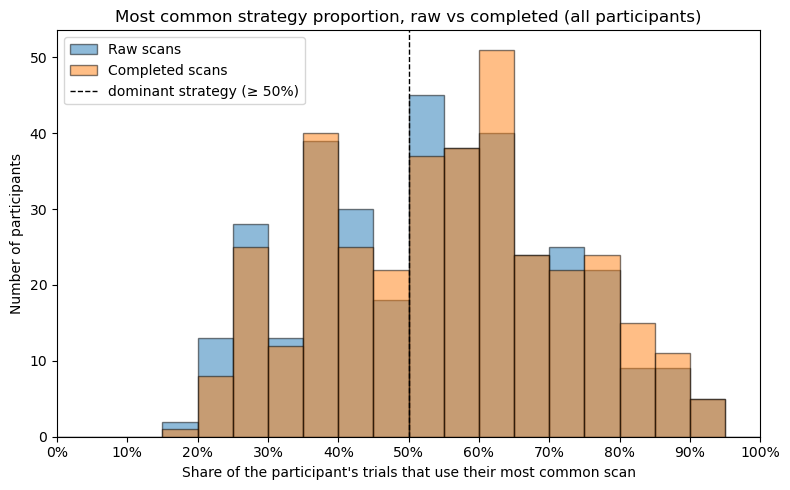

participants              360.000
mean_raw                    0.535
mean_completed              0.552
mean_delta                  0.017
raw_≥50%                   60.278
comp_≥50%                  63.056
changed_label_n             3.000
changed_label_pct           0.833
mean_seq_pct_changed        3.437
median_seq_pct_changed      1.852
dtype: float64

In [7]:
summary, per_person, _, _ = summarize_before_after(
    per_trial, raw_col=C.STRATEGY_COL, threshold=0.5, h_or_g="all_participants", save=False
)
pd.Series(summary).round(3)

## 4. How consistent is each person?

The distribution of dominance scores, from raw scans: the participants at 50% or more are the ones counted as having a dominant strategy. `strat_col="strategy_completed"` draws the completed version.

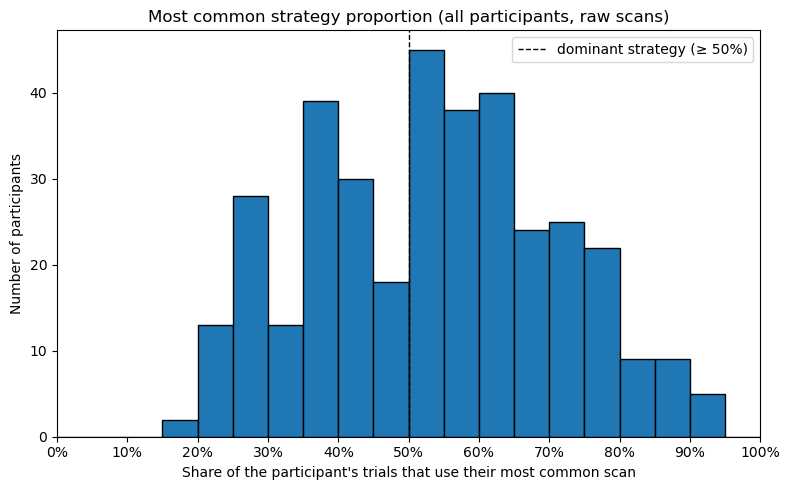

count    360.000
mean       0.535
std        0.174
min        0.185
25%        0.389
50%        0.537
75%        0.667
max        0.944
Name: dominance_score, dtype: float64

In [8]:
dominance = plot_dominant_strategy_hist(
    per_trial, strat_col=C.STRATEGY_COL, bins=20, figsize=(8, 5), h_or_g="all_participants", save=False
)
dominance.describe().round(3)

How far each person's most common scan is ahead of their second most common (raw scans). Left: the gap. Right: one point per participant; points well above the dashed line are people with one clear habit, points near it split their trials between two scans.

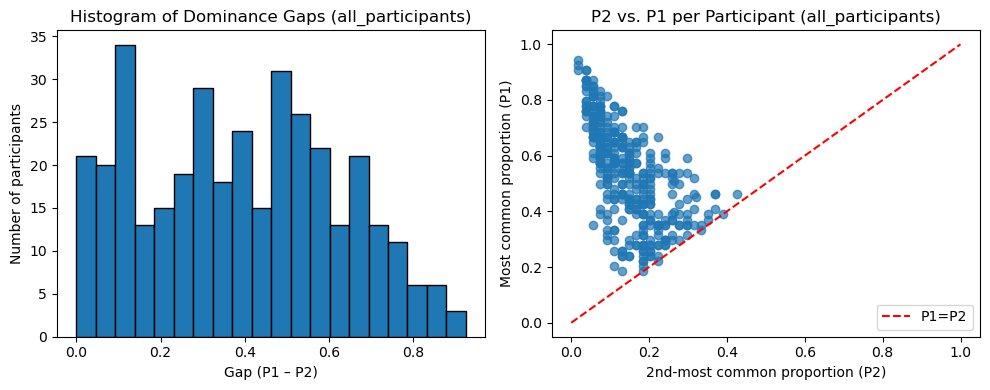

,p1,p2,gap
count,360.000,360.000,360.000
mean,0.535,0.147,0.388
std,0.174,0.079,0.232
min,0.185,0.019,0.000
25%,0.389,0.074,0.199
50%,0.537,0.130,0.389
75%,0.667,0.204,0.556
max,0.944,0.426,0.926


In [9]:
gap = plot_dominance_gap(
    per_trial, strat_col=C.STRATEGY_COL, bins=20, figsize=(10, 4), h_or_g="all_participants", save=False
)
gap.describe().round(3)

How many different opening scans each person used (raw scans). This is the counterweight to the dominance score: even people with a dominant scan used several others on the rest of their trials.

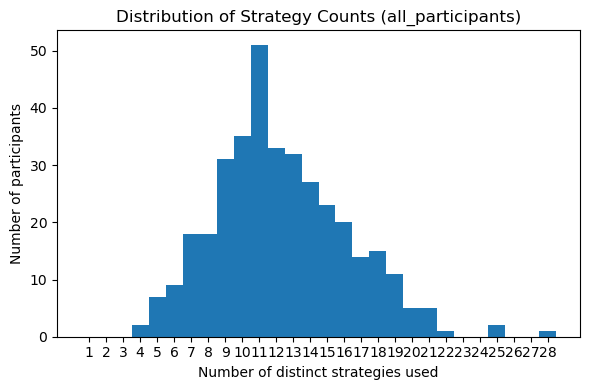

count    360.0
mean      12.3
std        3.9
min        4.0
25%       10.0
50%       12.0
75%       15.0
max       28.0
Name: strategy, dtype: float64

In [10]:
n_scans = plot_strategy_count_distribution(
    per_trial, strat_col=C.STRATEGY_COL, h_or_g="all_participants", save=False
)
n_scans.describe().round(1)

## 5. Which scans are dominant

Among participants who have a dominant strategy (completed scans, at least half of their trials), how many have each scan as theirs. The clockwise and counter-clockwise circuits account for most of them.

E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\src\analyses\scan_strategies\plots.py:277: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


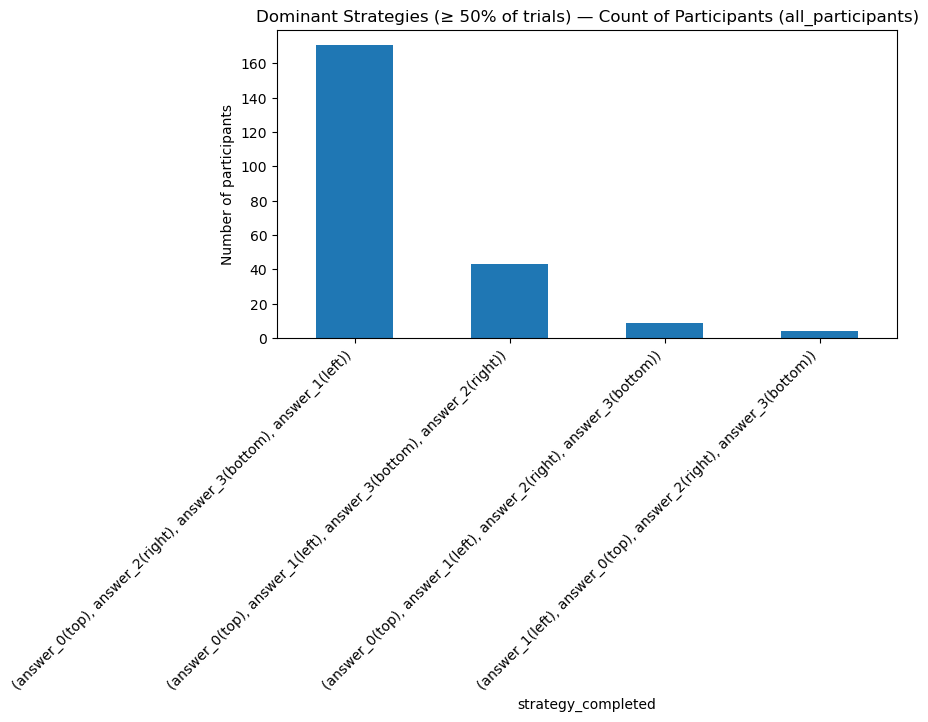

,participants
dominant_starting_strategy,
"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",171
"(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))",43
"(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))",9
"(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))",4


In [11]:
dominant_counts = plot_dominant_strategy_counts_above_threshold(
    per_trial, strat_col="strategy_completed", threshold=0.5, h_or_g="all_participants", save=False
)
dominant_counts.rename("participants").to_frame()

The same as shares, for raw and for completed scans: of the participants who have a dominant strategy, the percentage whose dominant scan is each one, and the percentage of all 360 participants.

In [12]:
from src.features.strategies import dominant_strategy_counts

n_all = per_trial[C.PARTICIPANT_ID].nunique()
tables = {}
for label, col in (("raw", C.STRATEGY_COL), ("completed", "strategy_completed")):
    n = dominant_strategy_counts(per_trial, strat_col=col, threshold=0.5)
    tables[label] = pd.DataFrame({
        "participants": n,
        "% of those with a dominant strategy": (100 * n / n.sum()).round(1),
        "% of all participants": (100 * n / n_all).round(1),
    })
pd.concat(tables, axis=1).fillna(0)

raw  \
                                                                   participants   
dominant_starting_strategy                                                        
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))          162   
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))           42   
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))            9   
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))            4   

                                                                                                        \
                                                                   % of those with a dominant strategy   
dominant_starting_strategy                                                                               
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))                                74.7   
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))                                19.4   
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))                                 4.1   
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))                                 1.8   

                                                                                          \
                                                                   % of all participants   
dominant_starting_strategy                                                                 
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))                  45.0   
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))                  11.7   
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))                   2.5   
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))                   1.1   

                                                                      completed  \
                                                                   participants   
dominant_starting_strategy                                                        
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))          171   
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))           43   
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))            9   
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))            4   

                                                                                                        \
                                                                   % of those with a dominant strategy   
dominant_starting_strategy                                                                               
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))                                75.3   
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))                                18.9   
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))                                 4.0   
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))                                 1.8   

                                                                                          
                                                                   % of all participants  
dominant_starting_strategy                                                                
(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))                  47.5  
(answer_0(top), answer_1(left), answer_3(bottom), answer_2(right))                  11.9  
(answer_0(top), answer_1(left), answer_2(right), answer_3(bottom))                   2.5  
(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))                   1.1

## 6. First and last visits

The same merged sequences as heatmaps: rows are visit positions (0 = first), columns are the four answers, and each cell counts trials. The function expects trials already filtered to one chosen answer; here, trials where the participant chose A, the correct answer. Trials whose sequence is empty once the question is removed are left out without a message.

First four answer visits, by screen position. Row 0 is mostly the top answer, and the rows after it trace the clockwise circuit.

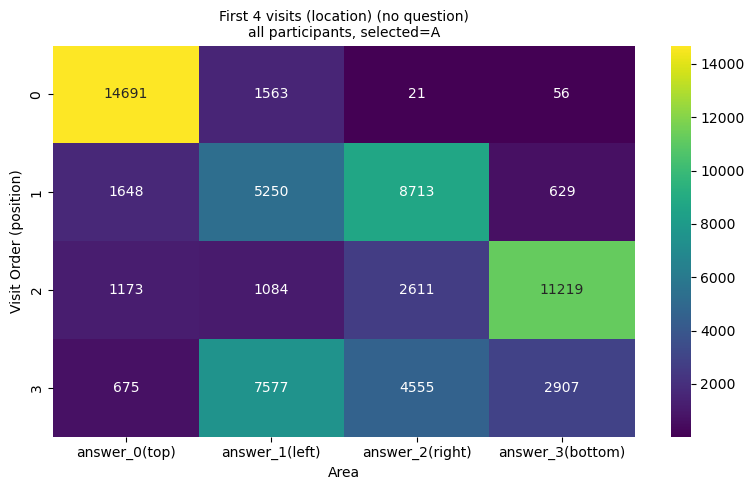

area,answer_0(top),answer_1(left),answer_2(right),answer_3(bottom)
position,,,,
0,14691,1563,21,56
1,1648,5250,8713,629
2,1173,1084,2611,11219
3,675,7577,4555,2907


In [13]:
chose_A = all_participants[all_participants[C.SELECTED_ANSWER_LABEL_COLUMN] == "A"]
_, _, first_by_position = matrix_plot_simplified_visits(
    chose_A, kind="location", which="first", drop_question=True,
    h_or_g="all participants", selected="A", save=False,
)
first_by_position

The same first four visits over **all** trials, whatever answer was chosen, as shares: each row sums to 100%, so a cell is the share of trials whose visit at that position went to that answer. The styling arguments give it plain labels for a slide.

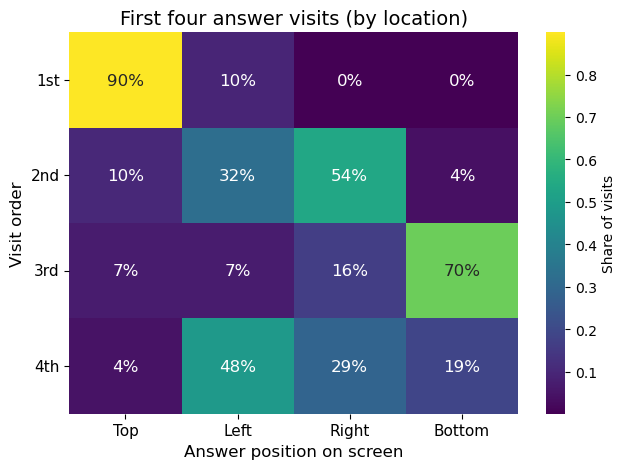

area,answer_0(top),answer_1(left),answer_2(right),answer_3(bottom)
position,,,,
0,0.899,0.096,0.001,0.003
1,0.102,0.324,0.536,0.038
2,0.071,0.068,0.163,0.697
3,0.044,0.482,0.289,0.186


In [14]:
_, _, first_shares = matrix_plot_simplified_visits(
    all_participants, kind="location", which="first", drop_question=True,
    h_or_g="all participants", selected="all",
    normalize="row", fmt=".0%",
    title="First four answer visits (by location)",
    xlabel="Answer position on screen", ylabel="Visit order",
    area_label_map={"answer_0(top)": "Top", "answer_1(left)": "Left",
                    "answer_2(right)": "Right", "answer_3(bottom)": "Bottom"},
    position_labels=["1st", "2nd", "3rd", "4th"], cbar_label="Share of visits",
    figsize=(6.5, 4.8), title_fontsize=14, label_fontsize=12, tick_fontsize=11, annot_fontsize=12,
    save=False,
)
first_shares.round(3)

Last four answer visits, by meaning (`kind="label"`; A is the correct answer). The rows count back from the end, so row 3 is always the final visit, also in a trial with fewer than four answer visits. When A was chosen, the final visit is mostly to A.

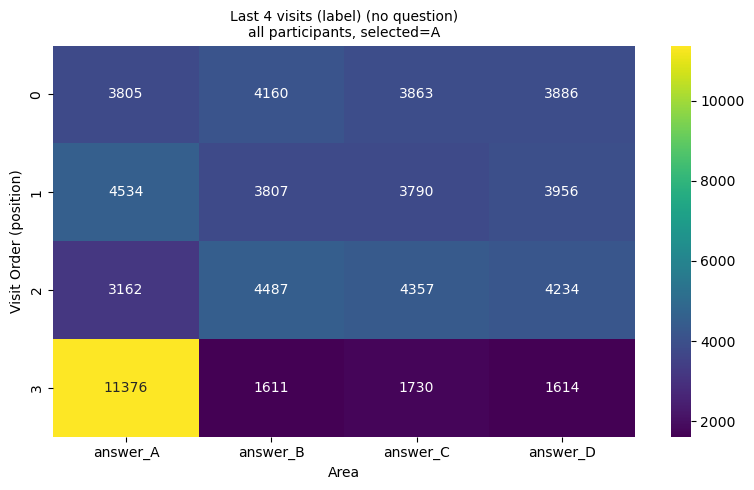

area,answer_A,answer_B,answer_C,answer_D
position,,,,
0,3805,4160,3863,3886
1,4534,3807,3790,3956
2,3162,4487,4357,4234
3,11376,1611,1730,1614


In [15]:
_, _, last_by_meaning_A = matrix_plot_simplified_visits(
    chose_A, kind="label", which="last", drop_question=True,
    h_or_g="all participants", selected="A", save=False,
)
last_by_meaning_A

The same for trials where B was chosen: the final visit moves to B, the chosen answer.

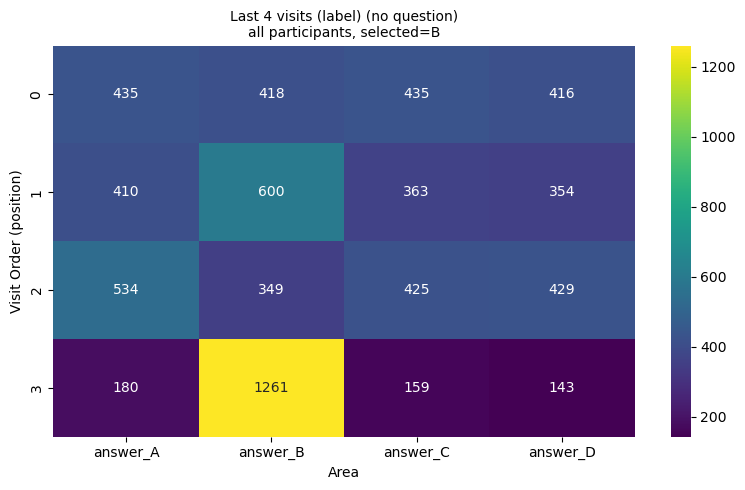

area,answer_A,answer_B,answer_C,answer_D
position,,,,
0,435,418,435,416
1,410,600,363,354
2,534,349,425,429
3,180,1261,159,143


In [16]:
chose_B = all_participants[all_participants[C.SELECTED_ANSWER_LABEL_COLUMN] == "B"]
_, _, last_by_meaning_B = matrix_plot_simplified_visits(
    chose_B, kind="label", which="last", drop_question=True,
    h_or_g="all participants", selected="B", save=False,
)
last_by_meaning_B

`run_all_simplified_visit_matrices` draws all 96 combinations: hunters, gatherers and all participants; chosen answer A to D; first or last visits; by position or by meaning; and with the question removed (`drop_question=True`) or kept, in which case the window is five visits.

## 7. Dominant scan and the dominant eye

The tracker records each participant's dominant eye, left or right (`EYE_TRACKED`). For each participant: their most common scan, how many of their trials use it (`n_trials` out of `n_total`), and their dominant eye.

In [17]:
by_eye = build_dominant_strategy_by_eye(all_participants, kind="location", window_len=4, drop_question=True)
by_eye.head()

,participant_id,EYE_TRACKED,dominant_strategy,n_trials,n_total,dominant_prop
0,l42_2070,Right,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",13,54,0.240741
1,l59_547,Right,"(answer_1(left), answer_0(top), answer_2(right), answer_3(bottom))",21,54,0.388889
2,l39_542,Right,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",15,54,0.277778
3,l56_522,Right,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",20,54,0.370370
4,l49_529,Right,"(answer_0(top), answer_2(right), answer_3(bottom), answer_1(left))",32,54,0.592593


One bar chart per eye: how many participants have each dominant scan. Then the scan-by-eye count table, most common scans first. Everyone is counted here, whatever their dominance score; `run_dominant_strategy_eye_analysis(..., threshold=0.5)` keeps only the participants with a dominant strategy. Descriptive only: no test is run, and the paper does not report it.

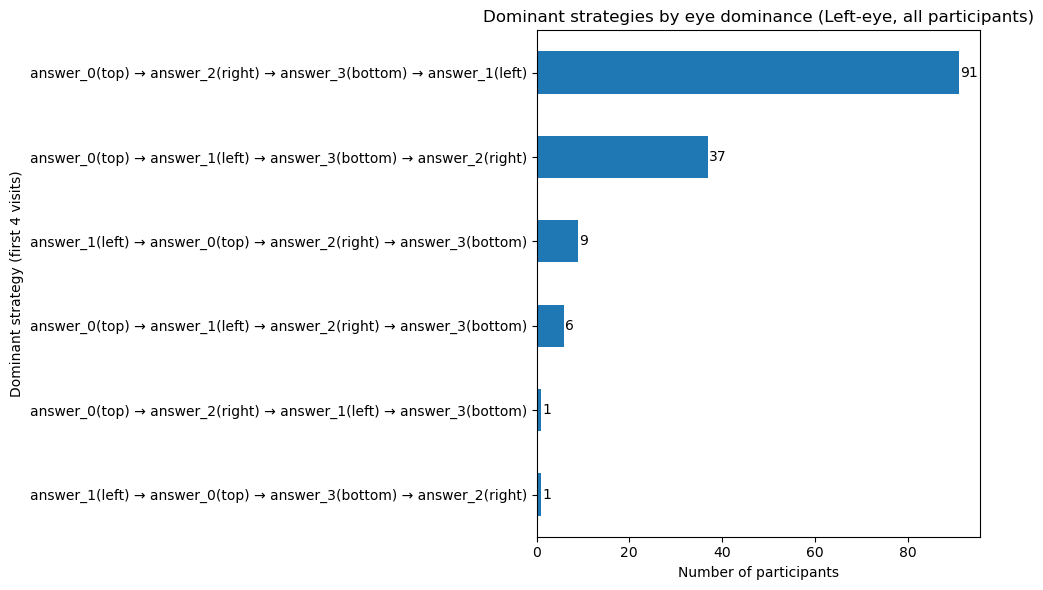

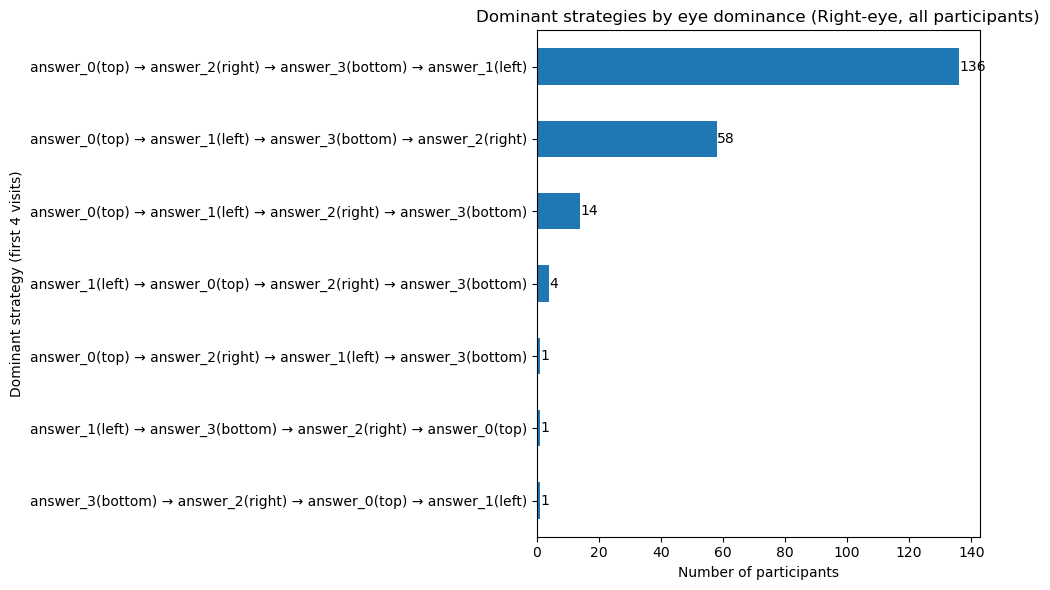

EYE_TRACKED,Left,Right
strategy_str,,
answer_0(top) → answer_2(right) → answer_3(bottom) → answer_1(left),91,136
answer_0(top) → answer_1(left) → answer_3(bottom) → answer_2(right),37,58
answer_0(top) → answer_1(left) → answer_2(right) → answer_3(bottom),6,14
answer_1(left) → answer_0(top) → answer_2(right) → answer_3(bottom),9,4
answer_0(top) → answer_2(right) → answer_1(left) → answer_3(bottom),1,1
answer_1(left) → answer_0(top) → answer_3(bottom) → answer_2(right),1,0
answer_1(left) → answer_3(bottom) → answer_2(right) → answer_0(top),0,1
answer_3(bottom) → answer_2(right) → answer_0(top) → answer_1(left),0,1


In [18]:
by_eye_counts = plot_dominant_strategies_by_eye_sorted(by_eye, group_name="all participants", save=False)
by_eye_counts.loc[by_eye_counts.sum(axis=1).sort_values(ascending=False).index].head(8)

## The rest

The runners draw these figures for every group and setting: `run_all_strategy_plots` (the dominance figures for hunters, gatherers and all participants; `kind="label"` names scans by meaning instead of position), `run_all_simplified_visit_matrices` (the 96 heatmaps) and `run_dominant_strategy_eye_analysis` (the eye charts for each group). `python scripts/run_analysis.py --name scan_strategies` runs all three and saves their figures and tables under `reports/scan_strategies/`.